# Install dependencies

In [1]:
import ee
import pandas as pd

# Trigger the authentication flow.
ee.Authenticate(auth_mode='notebook',force=False)

ee.Initialize()
# Use Earth Engine's default project

To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=0y0nZq-0mjiMK7lXpX60_3h8hYoB3D8Bjsf6fKB8VME&tc=FjNVyCwQebvEF4mAoKHsRTioEYBGpULdpApna_RDZXU&cc=7deKgkrZynDz6-P0nzUaAlhlNF0IbElnGkSVOQSfLK0

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AUn6Hd9SydSQmYTakhbSW0aFWqwqEyhExcYqa0ObUEnf1i8GJViFt-9KNmI

Successfully saved authorization token.


In [2]:
!pip install xarray netCDF4 rasterio numpy pandas matplotlib tqdm cartopy shapely geopandas us scipy rioxarray --quiet

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Get Alaska Polygon from GEE

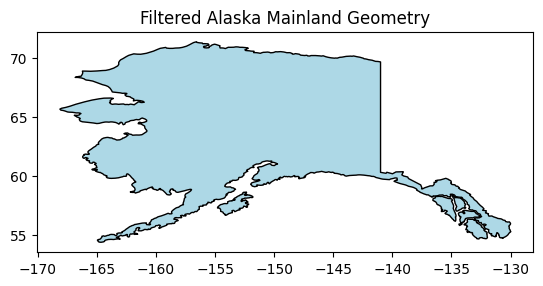

In [ ]:
import geopandas as gpd
from shapely.geometry import mapping

# === Load and filter Alaska shapefile ===
alaska_shp_path = "/content/drive/MyDrive/UND/Albedo/cb_2022_us_state_20m/cb_2022_us_state_20m.shp"
states = gpd.read_file(alaska_shp_path)
alaska = states[states['STUSPS'] == 'AK'].to_crs("EPSG:4326")

# Explode multipolygons
alaska = alaska.explode(index_parts=False)
alaska = alaska[alaska.geometry.bounds.maxx > -168]
alaska = alaska[alaska.geometry.bounds.maxy > 50]

# Project to Alaska Albers Equal Area (EPSG:3338) to compute area in m²
alaska_proj = alaska.to_crs("EPSG:3338")
alaska_proj["area_m2"] = alaska_proj.geometry.area

# Filter by area > 500 km² (500e6 m²)
alaska_proj = alaska_proj[alaska_proj["area_m2"] > 5e9]

# Back to WGS84 (EPSG:4326)
alaska_clean = alaska_proj.to_crs("EPSG:4326")

# Union to a single shape
mainland_geom = alaska_clean.union_all()
mainland_gdf = gpd.GeoDataFrame(geometry=[mainland_geom], crs="EPSG:4326")

# Save as GeoJSON
mainland_gdf.to_file("/content/drive/MyDrive/UND/Albedo/alaska_mainland.geojson", driver="GeoJSON")

import matplotlib.pyplot as plt
gpd.GeoSeries(mainland_geom).plot(color="lightblue", edgecolor="black")
plt.title("Filtered Alaska Mainland Geometry")
plt.show()

# Gather Target

In [ ]:
!wget -P "/content/drive/MyDrive/UND/Albedo/" https://github.com/jjmcnelis/mcd43-calculated-albedo/raw/master/sw_lut.csv

--2026-05-06 15:13:04--  https://github.com/jjmcnelis/mcd43-calculated-albedo/raw/master/sw_lut.csv
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/jjmcnelis/mcd43-calculated-albedo/master/sw_lut.csv [following]
--2026-05-06 15:13:04--  https://raw.githubusercontent.com/jjmcnelis/mcd43-calculated-albedo/master/sw_lut.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 27076 (26K) [text/plain]
Saving to: ‘/content/drive/MyDrive/UND/Albedo/sw_lut.csv’

sw_lut.csv          100%[===================>]  26.44K  --.-KB/s    in 0.005s  

2026-05-06 15:13:04 (4.77 MB/s) - ‘/content/drive/MyDrive/UND/Albe

In [ ]:
"""
Fit the diffuse-fraction polynomial S(SZA, AOD) to the actual Lewis (1995)
shortwave skyl LUT used by the MODIS BRDF/Albedo science team.

This is run ONCE on your machine. Output: 15 coefficients to paste into
the GEE script as SKYL_COEFS, plus a fit-quality report you can keep
in a methods section.

Setup
-----
    wget https://github.com/jjmcnelis/mcd43-calculated-albedo/raw/master/sw_lut.csv
    pip install numpy pandas scipy

Run
---
    python validate_skyl_polynomial.py
"""
from pathlib import Path

import numpy as np
import pandas as pd

LUT_PATH = Path("/content/drive/MyDrive/UND/Albedo/sw_lut.csv")

# ---------------------------------------------------------------------------
# 1. Load the real LUT
#
# File orientation (90 SZA rows x 50 AOD columns):
#   Rows    = SZA in degrees (0..89)
#   Columns = AOD550         (0.00..0.98 in 0.02 steps)
# ---------------------------------------------------------------------------
df = pd.read_csv(LUT_PATH, index_col=0)
sza_axis = df.index.to_numpy(dtype=float)            # (90,)
aod_axis = np.array([float(c) for c in df.columns])  # (50,)
S_table = df.values                                  # (90, 50)
print(f"Loaded LUT: {S_table.shape[0]} SZA x {S_table.shape[1]} AOD"
      f" = {S_table.size} points")
print(f"  SZA range: {sza_axis.min():.0f} to {sza_axis.max():.0f} deg")
print(f"  AOD range: {aod_axis.min():.2f} to {aod_axis.max():.2f}")
print(f"  S range:   {S_table.min():.3f} to {S_table.max():.3f}")


# ---------------------------------------------------------------------------
# 2. Build the training design matrix
#
# Polynomial form (tensor product, degree 4 in g, degree 2 in tau):
#
#    S(g, tau) = sum_{i=0..4} sum_{j=0..2} c[i,j] * g^i * tau^j
#
# 15 terms total. Higher degree in g is needed because S rises very steeply
# as SZA -> 90 deg (saturation toward 1), which a degree-2-in-g polynomial
# cannot capture (the previous fit had RMSE ~0.04 in S and max error ~0.29).
# ---------------------------------------------------------------------------
SZA_grid, AOD_grid = np.meshgrid(sza_axis, aod_axis, indexing='ij')  # (90, 50)
g = (1.0 - np.cos(np.deg2rad(SZA_grid))).ravel()
tau = AOD_grid.ravel()
y = S_table.ravel()

# 15-column design matrix
G_DEG, T_DEG = 4, 2
features = []
feature_names = []
for i in range(G_DEG + 1):
    for j in range(T_DEG + 1):
        features.append((g ** i) * (tau ** j))
        feature_names.append(f"c{i}{j}")
X = np.column_stack(features)

# Unconstrained least squares (we will check monotonicity post-hoc)
coefs, *_ = np.linalg.lstsq(X, y, rcond=None)
S_pred = X @ coefs
resid = S_pred - y
rmse = float(np.sqrt(np.mean(resid ** 2)))
maxerr = float(np.max(np.abs(resid)))


# ---------------------------------------------------------------------------
# 3. Print coefficients in the form the GEE script expects
# ---------------------------------------------------------------------------
print("\n" + "=" * 64)
print("FIT RESULT  (paste into SKYL_COEFS in the GEE script)")
print("=" * 64)
print("SKYL_COEFS = {")
for name, val in zip(feature_names, coefs):
    print(f"    '{name}': {val:+.6f},")
print("}")

print("\nFit quality (vs. the full 4500-point LUT):")
print(f"  RMSE in S:        {rmse:.4f}")
print(f"  Max |error| in S: {maxerr:.4f}")
print(f"  ==> Worst-case error in blue-sky albedo (|WSA-BSA| ~ 0.05):")
print(f"      RMSE      ~ {rmse * 0.05:.5f}  ({rmse * 0.05 * 100:.3f}%)")
print(f"      Max error ~ {maxerr * 0.05:.5f}  ({maxerr * 0.05 * 100:.3f}%)")
print(f"  MCD43A3 stated absolute accuracy: ~0.02")
print(f"  Polynomial-induced error is "
      f"{(maxerr * 0.05) / 0.02 * 100:.1f}% of product accuracy budget.")


# ---------------------------------------------------------------------------
# 4. Residuals broken down by region
# ---------------------------------------------------------------------------
SZA_flat = SZA_grid.ravel()
AOD_flat = AOD_grid.ravel()

print("\nResiduals by SZA range:")
for lo, hi in [(0, 30), (30, 60), (60, 80), (80, 89)]:
    m = (SZA_flat >= lo) & (SZA_flat <= hi)
    r = resid[m]
    print(f"  SZA in [{lo:>2}, {hi:>2}] deg: "
          f"RMSE={np.sqrt(np.mean(r**2)):.4f}, "
          f"max|err|={np.max(np.abs(r)):.4f}, n={m.sum()}")

print("\nResiduals by AOD range:")
for lo, hi in [(0.0, 0.1), (0.1, 0.3), (0.3, 0.6), (0.6, 1.0)]:
    m = (AOD_flat >= lo) & (AOD_flat <= hi)
    r = resid[m]
    print(f"  AOD in [{lo:.1f}, {hi:.1f}]: "
          f"RMSE={np.sqrt(np.mean(r**2)):.4f}, "
          f"max|err|={np.max(np.abs(r)):.4f}, n={m.sum()}")


# ---------------------------------------------------------------------------
# 5. Spot check (CORRECT indexing: S_table[sza_idx, aod_idx])
# ---------------------------------------------------------------------------
def predict(sza_deg, aod):
    g_ = 1.0 - np.cos(np.deg2rad(sza_deg))
    s = 0.0
    k = 0
    for i in range(G_DEG + 1):
        for j in range(T_DEG + 1):
            s += coefs[k] * (g_ ** i) * (aod ** j)
            k += 1
    return s

print("\nSpot check (LUT vs. polynomial fit at exact LUT cells):")
print(f"  {'SZA':>5} {'AOD':>6} {'LUT':>7} {'fit':>7} {'err':>8}")
for sza_q in [0, 30, 60, 80, 85, 89]:
    for aod_q in [0.04, 0.10, 0.20, 0.50]:
        sza_idx = int(np.argmin(np.abs(sza_axis - sza_q)))
        aod_idx = int(np.argmin(np.abs(aod_axis - aod_q)))
        sza_actual = sza_axis[sza_idx]
        aod_actual = aod_axis[aod_idx]
        true = S_table[sza_idx, aod_idx]   # CORRECT order: [SZA, AOD]
        fit = predict(sza_actual, aod_actual)
        print(f"  {sza_actual:>5.0f} {aod_actual:>6.2f} "
              f"{true:>7.3f} {fit:>7.3f} {fit - true:>+8.4f}")


# ---------------------------------------------------------------------------
# 6. Empirical monotonicity check on a fine grid
# ---------------------------------------------------------------------------
print("\nMonotonicity check on a fine grid:")
sza_fine = np.linspace(0, 89, 200)
aod_fine = np.linspace(0, 1, 200)

worst_dec_in_sza = 0.0
worst_dec_in_aod = 0.0
for aod_v in [0.0, 0.05, 0.1, 0.2, 0.4, 0.8]:
    s = np.array([predict(sz, aod_v) for sz in sza_fine])
    worst_dec_in_sza = min(worst_dec_in_sza, float(np.diff(s).min()))
for sza_v in [0, 30, 60, 80, 89]:
    s = np.array([predict(sza_v, ao) for ao in aod_fine])
    worst_dec_in_aod = min(worst_dec_in_aod, float(np.diff(s).min()))

print(f"  Worst step decrease in S as SZA increases: {worst_dec_in_sza:+.5f}")
print(f"  Worst step decrease in S as AOD increases: {worst_dec_in_aod:+.5f}")
print("  (Negative = small non-monotonic dip; if |dip| < 0.001 it's "
      "negligible.)")
print("  In the GEE script, S is clamped to [0, 1] post-evaluation, so "
      "small wiggles do not propagate.")

Loaded LUT: 90 SZA x 50 AOD = 4500 points
  SZA range: 0 to 89 deg
  AOD range: 0.00 to 0.98
  S range:   0.068 to 1.000

FIT RESULT  (paste into SKYL_COEFS in the GEE script)
SKYL_COEFS = {
    'c00': +0.081370,
    'c01': +0.491599,
    'c02': -0.131696,
    'c10': -0.429953,
    'c11': +1.700367,
    'c12': -0.937366,
    'c20': +3.392500,
    'c21': -8.831186,
    'c22': +4.864503,
    'c30': -7.216523,
    'c31': +18.757055,
    'c32': -9.809186,
    'c40': +4.969670,
    'c41': -11.138541,
    'c42': +5.200968,
}

Fit quality (vs. the full 4500-point LUT):
  RMSE in S:        0.0116
  Max |error| in S: 0.1380
  ==> Worst-case error in blue-sky albedo (|WSA-BSA| ~ 0.05):
      RMSE      ~ 0.00058  (0.058%)
      Max error ~ 0.00690  (0.690%)
  MCD43A3 stated absolute accuracy: ~0.02
  Polynomial-induced error is 34.5% of product accuracy budget.

Residuals by SZA range:
  SZA in [ 0, 30] deg: RMSE=0.0035, max|err|=0.0134, n=1550
  SZA in [30, 60] deg: RMSE=0.0041, max|err|=0.0200,

In [5]:
"""
Daily blue-sky shortwave albedo over Alaska -- Google Earth Engine export (v3).

v3 IS FOR REGATHERING THE WHOLE ARCHIVE with two changes to what goes into
each 1 km pixel. Both are switches in the configuration block:

  AGGREGATE = True   Area-weighted mean of the native 463 m MCD43A3 pixels
                     that pass QA, computed with reduceResolution(). QA is
                     applied to every native pixel BEFORE averaging.
                     Without this (v1/v2), a 1 km export makes GEE read the
                     926 m pyramid level (albedo = mean of 2x2 native pixels,
                     QA band built separately -- discrete bands are normally
                     "sampled", i.e. one pixel), then nearest-neighbour
                     resample to 1 km. QA and albedo could therefore describe
                     different native pixels.
  QA_MAX = 1         Keep magnitude BRDF inversions (QA 1) as well as full
                     inversions (QA 0). A companion file per year records,
                     for every valid value, the % of its area that came from
                     full inversions, so the choice stays reversible.

  How the pieces fit: BSA, WSA and the QA masks are averaged at native
  resolution; the diffuse fraction S (solar geometry + MAIAC AOD) is computed
  on the 1 km grid. Because alpha = (1 - S) BSA + S WSA is linear in BSA and
  WSA and S is constant within a 1 km cell, this equals averaging alpha
  itself -- while the expensive AOD step stays at 1 km.

Carried over from v2: clipped inside GEE on a grid pinned to the existing
archive (crs + crsTransform + dimensions), MAIAC filtered by date and region
before mapping, SMOKE_TEST mode, skip-if-exists / skip-if-running guards,
verify_export(). New: a settings manifest per output folder (refuses to mix
settings in one folder) and compare_to_archive() for the smoke test.

METHOD (NASA-standard; Schaaf et al. 2002, Lucht et al. 2000, Roman et al. 2010)
    alpha = (1 - S) * BSA + S * WSA
    BSA = MCD43A3.061 Albedo_BSA_shortwave at local solar noon.
    WSA = MCD43A3.061 Albedo_WSA_shortwave.
    S   = diffuse fraction = f(SZA, AOD550), 15-term polynomial fit to the
          Lewis (1995) shortwave skyl LUT; monotonic in SZA over Alaska's
          noon-SZA range (>= 31 deg), dips slightly in AOD only for
          SZA > 76 deg with AOD > 0.7. Clamped to [0, 1].
    SZA = |latitude - declination| at local solar noon (Spencer 1971).
    AOD = MCD19A2.061 MAIAC Optical_Depth_055, QA-filtered daily mean,
          gap-filled: same day -> +/- AOD_FILL_DAYS window -> AOD_CLIMO.

QUALITY CONTROL
    - MCD43A3 BRDF_Albedo_Band_Mandatory_Quality_shortwave <= QA_MAX
      (0 = full inversion, 1 = magnitude inversion)
    - MCD43A2 BRDF_Albedo_LandWaterType == 1 (land only; with AGGREGATE,
      water counts as invalid area, so mostly-water coastal cells drop out)
    - AGGREGATE only: >= MIN_VALID_FRAC of the 1 km cell area must be valid
    - MCD19A2 AOD_QA: clear, not adjacent to cloud/snow, best quality, AOD >= 0
    - Polar-night mask (solar-noon SZA >= SZA_MAX)
    - No terrain correction (MCD43A3 is a flat-surface product)

OUTPUT (per year, EPSG:3338, grid of GRID_TEMPLATE, clipped to the AOI)
    DRIVE_FOLDER/BlueSky_albedo_daily_YYYY.tif
        int16, albedo * 1e4, NoData -32768.
    QA_FOLDER/BlueSky_pctfull_daily_YYYY.tif        (if EXPORT_QA)
        uint8, % of the value's area from full inversions (0-100), NoData 255.
        Same NoData pattern as the albedo file.
    One band per available day, named 'dYYYYMMDD', chronological; fully
    masked days are present as all-NoData bands.
    The QA files MUST stay in their own folder: albedo_dataset.py indexes
    every *.tif in data_dir by its dYYYYMMDD band names.

REFERENCES
    Schaaf et al. (2002) RSE 83, 135-148.  Lucht et al. (2000) IEEE TGRS 38,
    977-998.  Lewis (1995) IGARSS.  Roman et al. (2010) RSE 114, 738-760.
    Spencer (1971) Search 2(5), 172.  Lyapustin et al. (2018) MCD19 user guide.
"""

# %% ==========================================================================
# CELL 1 -- setup, configuration, functions
# =============================================================================
import datetime as dt
import glob
import json
import math
import os

import ee
import geopandas as gpd
import rasterio                      # !pip install rasterio  (if missing in Colab)
from pyproj import Transformer

# =============================================================================
# CONFIGURATION
# =============================================================================
EE_PROJECT   = None                  # your Cloud project id, or None for the default
ALBEDO_ROOT  = "/content/drive/MyDrive/UND/Albedo"
GEOJSON_PATH = f"{ALBEDO_ROOT}/alaska_mainland.geojson"

# Drive exports take a folder NAME that must be unique in your Drive, not a
# path. Cell 2 creates both folders under UND/Albedo before submitting, so GEE
# writes there. New folders keep the old archive intact for comparison.
DRIVE_FOLDER = "BlueSky_Daily_TIFFs_v4"
QA_FOLDER    = "BlueSky_Daily_QA_TIFFs_v4"
SMOKE_FOLDER = "BlueSky_smoke_tests"          # GEE creates it at My Drive root
FILE_PREFIX  = "BlueSky_albedo_daily_{year}"
QA_PREFIX    = "BlueSky_pctfull_daily_{year}"

YEARS = list(range(2026, 2027))      # 2026 is partial (MCD43A3 ends 2026-10 in GEE)

# Output grid: copied from the existing archive, so the new files are drop-in
# replacements (same origin and size; your MATLAB checkOrigin() relies on it).
GRID_TEMPLATE = f"{ALBEDO_ROOT}/BlueSky_Daily_TIFFs_Clipped/BlueSky_albedo_daily_2025.tif"
SCALE = 1000                         # m; used only when GRID_TEMPLATE is None
CRS   = "EPSG:3338"                  # Alaska Albers

# --- what goes into each 1 km pixel -----------------------------------------
QA_MAX         = 1       # 0: full BRDF inversions only (v1/v2)  1: + magnitude inversions
AGGREGATE      = True    # True: area-weighted mean of valid native pixels (reduceResolution)
                         # False: GEE default resampling, as in v1/v2
MIN_VALID_FRAC = 0.5     # AGGREGATE only: keep a cell if >= this share of its area is valid
MAX_PIX        = 128     # reduceResolution limit per output pixel. 13-18 native pixels
                         # touch a 1 km cell anywhere in Alaska (up to 36 in the bbox)
EXPORT_QA      = QA_MAX >= 1   # companion % full-inversion file (pointless when QA_MAX = 0)

AOD_FILL_DAYS = 8                    # +/- window for AOD temporal gap-fill
AOD_CLIMO     = 0.10                 # final fallback: Alaska annual MAIAC mean
SZA_MAX       = 89.0                 # mask polar-night pixels at/above this
LAND_YEAR     = 2010                 # land/water type = its most frequent value in this year

SCALE_TO_INT16 = True                # False -> float32 (4x larger files)
NODATA         = -32768
QA_NODATA      = 255

# Run this first. 21 spring days over a 200 x 200 km box in south-central
# Alaska (Kenai / Cook Inlet / Anchorage): maritime, cloudy, melting -- where
# QA <= 1 should matter most. 2025 so compare_to_archive() has a reference.
SMOKE_TEST   = False
SMOKE_YEAR   = 2025
SMOKE_DATES  = ("04-20", "05-11")    # [start, end)
SMOKE_CENTER = (-150.5, 60.9)        # lon, lat
SMOKE_SIZE   = 200                   # pixels

ee.Initialize(project=EE_PROJECT)


# =============================================================================
# AOI (client side: read once, used for the clip and for verification)
# =============================================================================
with open(GEOJSON_PATH) as f:
    AOI_FC = ee.FeatureCollection(json.load(f))   # all features, not just [0]
AK_3338 = gpd.read_file(GEOJSON_PATH).to_crs(CRS)


# =============================================================================
# OUTPUT GRID (client side)
# =============================================================================
def grid_from_template(path):
    """crsTransform and size of an existing EPSG:3338 GeoTIFF."""
    with rasterio.open(path) as src:
        if src.crs is None or src.crs.to_epsg() != 3338:
            raise ValueError(f"{path}: expected EPSG:3338, found {src.crs}")
        t = src.transform
        return {"crsTransform": [t.a, t.b, t.c, t.d, t.e, t.f],
                "width": src.width, "height": src.height}


def grid_from_bounds(bounds, scale):
    """Grid covering (xmin, ymin, xmax, ymax), origin snapped outward to scale."""
    xmin, ymin, xmax, ymax = bounds
    x0, x1 = math.floor(xmin / scale) * scale, math.ceil(xmax / scale) * scale
    y0, y1 = math.floor(ymin / scale) * scale, math.ceil(ymax / scale) * scale
    return {"crsTransform": [scale, 0, x0, 0, -scale, y1],
            "width": int(round((x1 - x0) / scale)),
            "height": int(round((y1 - y0) / scale))}


def subgrid(grid, lon, lat, size_px):
    """A size_px x size_px block of `grid` centred on (lon, lat), same alignment."""
    a, b, c, d, e, f = grid["crsTransform"]
    x, y = Transformer.from_crs("EPSG:4326", CRS, always_xy=True).transform(lon, lat)
    col = int((x - c) // a) - size_px // 2
    row = int((y - f) // e) - size_px // 2
    return {"crsTransform": [a, b, c + col * a, d, e, f + row * e],
            "width": size_px, "height": size_px}


def grid_rectangle(grid):
    """The grid's footprint as a planar EPSG:3338 rectangle (for filterBounds)."""
    a, _, c, _, e, f = grid["crsTransform"]
    x1 = c + grid["width"] * a
    y0 = f + grid["height"] * e
    return ee.Geometry.Rectangle([c, y0, x1, f], CRS, False)


GRID = (grid_from_template(GRID_TEMPLATE) if GRID_TEMPLATE
        else grid_from_bounds(AK_3338.total_bounds, SCALE))
if SMOKE_TEST:
    GRID = subgrid(GRID, *SMOKE_CENTER, SMOKE_SIZE)
GRID_RECT = grid_rectangle(GRID)
print(f"Grid: {GRID['width']} x {GRID['height']} px, transform {GRID['crsTransform']}")


# =============================================================================
# DIFFUSE-FRACTION POLYNOMIAL
#     S(g, tau) = sum_{i=0..4} sum_{j=0..2} c_ij * g^i * tau^j,
#     g = 1 - cos(SZA),  tau = AOD550.
# Coefficients from validate_skyl_polynomial.py (fit to sw_lut.csv from
# github.com/jjmcnelis/mcd43-calculated-albedo).
# =============================================================================
SKYL_COEFS = {
    'c00': +0.081370, 'c01': +0.491599, 'c02': -0.131696,
    'c10': -0.429953, 'c11': +1.700367, 'c12': -0.937366,
    'c20': +3.392500, 'c21': -8.831186, 'c22': +4.864503,
    'c30': -7.216523, 'c31': +18.757055, 'c32': -9.809186,
    'c40': +4.969670, 'c41': -11.138541, 'c42': +5.200968,
}


# =============================================================================
# COLLECTIONS AND STATIC LAYERS
# =============================================================================
MCD43A3 = ee.ImageCollection("MODIS/061/MCD43A3")
MAIAC   = ee.ImageCollection("MODIS/061/MCD19A2_GRANULES")   # global granules

BSA_BAND = 'Albedo_BSA_shortwave'
WSA_BAND = 'Albedo_WSA_shortwave'
QC_BAND  = 'BRDF_Albedo_Band_Mandatory_Quality_shortwave'
INPUT_BANDS = [BSA_BAND, WSA_BAND, QC_BAND]

# Native MODIS sinusoidal grid (463 m): the resolution reduceResolution reads.
MODIS_PROJ = MCD43A3.first().select(BSA_BAND).projection()

LATITUDE = ee.Image.pixelLonLat().select('latitude')

# MCD43A2 land mask from one date: include strictly land (1) and shorelines (2)
# LAND = (ee.ImageCollection("MODIS/061/MCD43A2")
#         .filterDate('2010-07-01', '2010-07-02')
#         .select('BRDF_Albedo_LandWaterType')
#         .first()
#         .eq(1))                                              # 1 = land
lwt = (ee.ImageCollection("MODIS/061/MCD43A2")
        .filterDate(f'{LAND_YEAR}-01-01', f'{LAND_YEAR + 1}-01-01')
        .select('BRDF_Albedo_LandWaterType')
        .reduce(ee.Reducer.mode()))
LAND = lwt.eq(1).Or(lwt.eq(2))

# =============================================================================
# PHYSICS
# =============================================================================
def solar_noon_sza(date):
    """Per-pixel SZA (deg) at local solar noon, Spencer (1971) declination."""
    doy = ee.Number(date.getRelative('day', 'year')).add(1)  # 1..366
    gamma = doy.subtract(1).multiply(2.0 * math.pi / 365.0)  # day angle, rad
    decl_rad = (ee.Number(0.006918)
                .subtract(gamma.cos().multiply(0.399912))
                .add(gamma.sin().multiply(0.070257))
                .subtract(gamma.multiply(2).cos().multiply(0.006758))
                .add(gamma.multiply(2).sin().multiply(0.000907))
                .subtract(gamma.multiply(3).cos().multiply(0.002697))
                .add(gamma.multiply(3).sin().multiply(0.001480)))
    decl_deg = decl_rad.multiply(180.0 / math.pi)
    return LATITUDE.subtract(decl_deg).abs()


def diffuse_fraction(sza, tau):
    """S(g, tau) by Horner's rule in both variables, clamped to [0, 1]
    (identical to the expanded 15-term sum to 3e-15)."""
    c = SKYL_COEFS
    g = ee.Image(1).subtract(sza.multiply(math.pi / 180.0).cos())

    def p(i):   # c_i0 + tau * (c_i1 + tau * c_i2)
        return tau.multiply(c[f'c{i}2']).add(c[f'c{i}1']).multiply(tau).add(c[f'c{i}0'])

    S = p(4)
    for i in (3, 2, 1, 0):
        S = S.multiply(g).add(p(i))
    return S.clamp(0.0, 1.0)


# =============================================================================
# AOD (MAIAC)
# =============================================================================
def _maiac_clean(img):
    """QA-filtered AOD band (MCD19A2 v6.1 user guide), as float.
        bits 0-2 cloud mask == 001 (clear); bits 5-7 adjacency == 000;
        bits 8-11 AOD QA == 0000 (best); AOD >= 0.
    """
    qa = img.select('AOD_QA')
    aod = img.select('Optical_Depth_055')
    ok = (qa.bitwiseAnd(0b111).eq(1)
          .And(qa.rightShift(5).bitwiseAnd(0b111).eq(0))
          .And(qa.rightShift(8).bitwiseAnd(0b1111).eq(0))
          .And(aod.gte(0)))
    return aod.updateMask(ok).toFloat()


def build_daily_aod(start, end, region):
    """One image per calendar day over [start - window, end + window): the mean
    of that day's QA-filtered MAIAC granules (raw units, x0.001). Days without
    a valid retrieval are fully masked (not missing)."""
    buf_start = ee.Date(start).advance(-AOD_FILL_DAYS, 'day')
    buf_end   = ee.Date(end).advance(AOD_FILL_DAYS, 'day')

    maiac = (MAIAC.filterDate(buf_start, buf_end)        # filter first ...
                  .filterBounds(region)
                  .select(['Optical_Depth_055', 'AOD_QA']))   # ... select first

    # A fully masked image keeps .mean() well-defined on days with no granule.
    scaffold = (ee.Image.constant(0).toFloat()
                .rename('Optical_Depth_055')
                .updateMask(ee.Image.constant(0)))

    def one_day(offset):
        d0 = buf_start.advance(ee.Number(offset), 'day')
        day_mean = (maiac.filterDate(d0, d0.advance(1, 'day'))
                         .map(_maiac_clean)
                         .merge(ee.ImageCollection([scaffold]))
                         .mean())
        return day_mean.set('system:time_start', d0.millis())

    n_days = buf_end.difference(buf_start, 'day').toInt()
    return ee.ImageCollection(ee.List.sequence(0, n_days.subtract(1)).map(one_day))


def gapfilled_aod(daily_aod, date):
    """AOD550 for `date`: same-day mean -> +/- window mean -> climatology."""
    aod_day = (daily_aod.filterDate(date, date.advance(1, 'day'))
               .mean().multiply(0.001).clamp(0.0, 1.0))
    aod_win = (daily_aod.filterDate(date.advance(-AOD_FILL_DAYS, 'day'),
                                    date.advance(AOD_FILL_DAYS + 1, 'day'))
               .mean().multiply(0.001).clamp(0.0, 1.0))
    return aod_day.unmask(aod_win).unmask(ee.Image.constant(AOD_CLIMO))


# =============================================================================
# PER-PIXEL INPUTS: QA, AVERAGING, VALIDITY
# =============================================================================
def _area_mean(img):
    """Area-weighted mean of native 463 m pixels onto the export grid.
    Weights = input mask x fraction of the output pixel it covers, so masked
    pixels drop out. No reproject(): the export's crs/crsTransform set the
    output grid; setDefaultProjection tells GEE what 'native' means for images
    built from comparisons and unmask()."""
    return (img.setDefaultProjection(MODIS_PROJ)
               .reduceResolution(ee.Reducer.mean(), False, MAX_PIX))


def albedo_inputs(img, sza):
    """For one MCD43A3 day, on the export grid:
        bsa, wsa  -- unitless, from QA-passing native pixels
        valid     -- 1 where a value should be written
        pct_full  -- % of the value's area from full inversions (QA == 0)
    `valid` is the SAME for the albedo and the QA companion file."""
    qc = img.select(QC_BAND)
    bw = img.select([BSA_BAND, WSA_BAND])
    ok = (qc.lte(QA_MAX).And(LAND)                       # per native pixel
          .And(bw.select(0).mask()).And(bw.select(1).mask()))

    if AGGREGATE:
        ok = ok.unmask(0)                                # 0/1 everywhere
        frac = _area_mean(ok)                            # valid share of cell area
        full_frac = _area_mean(qc.eq(0).And(ok).unmask(0))
        bw = _area_mean(bw.updateMask(ok))
        valid = frac.gte(MIN_VALID_FRAC)
        pct_full = full_frac.divide(frac).multiply(100)
    else:
        valid = ok
        pct_full = qc.eq(0).multiply(100)

    valid = valid.And(sza.lt(SZA_MAX))
    bw = bw.multiply(0.001)
    return bw.select(0), bw.select(1), valid, pct_full


def _tag(result, img, name):
    return ee.Image(result.rename(name)
                    .copyProperties(img, ['system:time_start', 'system:index']))


def make_albedo_processor(daily_aod):
    def process(img):
        date = ee.Date(img.get('system:time_start'))
        sza = solar_noon_sza(date)                       # on the 1 km grid
        bsa, wsa, valid, _ = albedo_inputs(img, sza)
        S = diffuse_fraction(sza, gapfilled_aod(daily_aod, date))
        alpha = ee.Image(1).subtract(S).multiply(bsa).add(S.multiply(wsa))
        return _tag(alpha.updateMask(valid), img, 'blue_sky_albedo')
    return process


def qa_processor(img):
    """Companion value; needs no AOD, so it is cheap."""
    sza = solar_noon_sza(ee.Date(img.get('system:time_start')))
    _, _, valid, pct_full = albedo_inputs(img, sza)
    return _tag(pct_full.updateMask(valid), img, 'pct_full')


# =============================================================================
# YEARLY STACKS
# =============================================================================
def _to_bands(daily):
    names = (daily.aggregate_array('system:time_start')
             .map(lambda t: ee.String('d').cat(ee.Date(t).format('YYYYMMdd'))))
    return daily.toBands().rename(names)


def _days(start, end, processor):
    return (MCD43A3.filterDate(start, end)
                   .select(INPUT_BANDS)
                   .map(processor)
                   .sort('system:time_start'))


def albedo_stack(start, end, region):
    """int16 (albedo x 1e4) or float32, one band per MCD43A3 day in [start, end)."""
    daily_aod = build_daily_aod(start, end, region)
    stack = _to_bands(_days(start, end, make_albedo_processor(daily_aod)))
    stack = (stack.multiply(10000).round().toInt16() if SCALE_TO_INT16
             else stack.toFloat())
    # One clip on the final image, then explicit NoData outside Alaska / QA.
    return stack.clipToCollection(AOI_FC).unmask(NODATA, False)


def qa_stack(start, end):
    """uint8 % full-inversion area, same bands and NoData pattern as albedo_stack."""
    stack = _to_bands(_days(start, end, qa_processor)).round().toUint8()
    return stack.clipToCollection(AOI_FC).unmask(QA_NODATA, False)


# =============================================================================
# SUBMISSION HELPERS (client side)
# =============================================================================
def settings():
    return {"QA_MAX": QA_MAX, "AGGREGATE": AGGREGATE,
            "MIN_VALID_FRAC": MIN_VALID_FRAC if AGGREGATE else None,
            "AOD_FILL_DAYS": AOD_FILL_DAYS, "AOD_CLIMO": AOD_CLIMO, "SZA_MAX": SZA_MAX,
            "SCALE_TO_INT16": SCALE_TO_INT16, "CRS": CRS,
            "crsTransform": GRID["crsTransform"],
            "size": [GRID["width"], GRID["height"]],
            "SKYL_COEFS": SKYL_COEFS}


def prepare_folder(folder):
    """Create the output folder under UND/Albedo and write/check its manifest.
    Refuses to add files made with different settings to an existing folder."""
    path = os.path.join(ALBEDO_ROOT, folder)
    os.makedirs(path, exist_ok=True)
    manifest = os.path.join(path, "export_settings.json")
    now = settings()
    if os.path.exists(manifest):
        with open(manifest) as f:
            old = json.load(f)
        diff = {k: (old.get("settings", {}).get(k), v)
                for k, v in now.items() if old.get("settings", {}).get(k) != v}
        if diff:
            raise RuntimeError(f"{folder} holds files made with other settings "
                               f"(was, now): {diff}. Use a new folder.")
    else:
        with open(manifest, "w") as f:
            json.dump({"created": dt.datetime.now(dt.timezone.utc).isoformat(),
                       "script": "gee_bluesky_albedo_export.py v3",
                       "earthengine_api": ee.__version__,
                       "settings": now}, f, indent=2)


def available_dates(start, end):
    """MCD43A3 dates in [start, end) -- metadata only, one small request."""
    ms = MCD43A3.filterDate(start, end).aggregate_array('system:time_start').getInfo()
    return [dt.datetime.fromtimestamp(m / 1000, dt.timezone.utc).date() for m in ms]


def active_task_descriptions():
    try:
        return {t.get('description') for t in ee.data.getTaskList()
                if t.get('state') in ('READY', 'RUNNING')}
    except Exception as exc:                       # never block on this check
        print(f"  (could not list tasks: {exc})")
        return set()


def existing_outputs(folder, prefix):
    """Files for `prefix` already in `folder` (as seen from the Colab mount)."""
    return sorted(glob.glob(os.path.join(ALBEDO_ROOT, folder, prefix + '*.tif')))


def submit(image, prefix, folder, nodata):
    task = ee.batch.Export.image.toDrive(
        image=image,
        description=prefix,
        folder=folder,
        fileNamePrefix=prefix,
        crs=CRS,
        crsTransform=GRID['crsTransform'],
        dimensions=f"{GRID['width']}x{GRID['height']}",
        maxPixels=1e10,
        formatOptions={'noData': nodata},
    )
    task.start()
    return task


def show_pyramiding_policy():
    """How GEE aggregates MCD43A3 bands into its pyramid (what v1/v2 read at 1 km)."""
    try:
        asset_id = MCD43A3.filterDate(f"{SMOKE_YEAR}-06-01", f"{SMOKE_YEAR}-06-02") \
                          .first().get('system:id').getInfo()
        for b in ee.data.getAsset(asset_id).get('bands', []):
            if b.get('id') in INPUT_BANDS:
                print(f"  pyramiding {b['id']}: {b.get('pyramidingPolicy', 'not reported')}")
    except Exception as exc:
        print(f"  (could not read pyramiding policy: {exc})")


# %% ==========================================================================
# CELL 2 -- submit exports
# =============================================================================
if SMOKE_TEST:
    years, folders = [SMOKE_YEAR], {"alb": SMOKE_FOLDER, "qa": SMOKE_FOLDER}
    show_pyramiding_policy()
else:
    years, folders = YEARS, {"alb": DRIVE_FOLDER, "qa": QA_FOLDER}
    prepare_folder(DRIVE_FOLDER)
    if EXPORT_QA:
        prepare_folder(QA_FOLDER)

active = active_task_descriptions()
tasks = []

for year in years:
    if SMOKE_TEST:
        start, end = (f"{year}-{SMOKE_DATES[0]}", f"{year}-{SMOKE_DATES[1]}")
        tag = "SMOKE_"
    else:
        start, end = f"{year}-01-01", f"{year + 1}-01-01"
        tag = ""
    jobs = [("alb", tag + FILE_PREFIX.format(year=year), NODATA)]
    if EXPORT_QA:
        jobs.append(("qa", tag + QA_PREFIX.format(year=year), QA_NODATA))

    # Skip what is already on Drive or already queued.
    todo = []
    for kind, prefix, nodata in jobs:
        found = [] if SMOKE_TEST else existing_outputs(folders[kind], prefix)
        if found:
            print(f"{year}: {os.path.basename(found[0])} exists -- skipped "
                  f"(delete it to re-export; Drive keeps duplicate names).")
        elif prefix in active:
            print(f"{year}: '{prefix}' is already queued/running -- skipped.")
        else:
            todo.append((kind, prefix, nodata))
    if not todo:
        continue

    dates = available_dates(start, end)
    if not dates:
        print(f"{year}: no MCD43A3 images in [{start}, {end}) -- skipped.")
        continue
    span = (dates[-1] - dates[0]).days + 1
    partial = (not SMOKE_TEST) and dates[-1] < dt.date(year, 12, 31)
    print(f"{year}: {len(dates)} bands, {dates[0]} -> {dates[-1]}"
          f"{f', {span - len(dates)} missing day(s)' if span != len(dates) else ''}"
          f"{'  [PARTIAL YEAR: re-export after it closes]' if partial else ''}")

    for kind, prefix, nodata in todo:
        image = albedo_stack(start, end, GRID_RECT) if kind == "alb" else qa_stack(start, end)
        tasks.append((year, submit(image, prefix, folders[kind], nodata)))

print(f"\n{len(tasks)} task(s) submitted. Monitor: https://code.earthengine.google.com/tasks")


# %% ==========================================================================
# CELL 3 -- verify an export once it is on Drive (run after the task ends)
# =============================================================================
def verify_export(path, template=GRID_TEMPLATE):
    """Grid, band dates, value range, and pixels outside Alaska."""
    import numpy as np
    import pandas as pd
    from rasterio.features import geometry_mask

    with rasterio.open(path) as src:
        name = os.path.basename(path)
        print(name)
        if template and not name.startswith("SMOKE_"):
            with rasterio.open(template) as ref:
                same = (src.crs == ref.crs
                        and np.allclose(tuple(src.transform)[:6], tuple(ref.transform)[:6])
                        and (src.width, src.height) == (ref.width, ref.height))
            print(f"  grid identical to template : {same}")
        nd = src.nodata
        print(f"  size {src.width} x {src.height}, {src.count} bands, {src.dtypes[0]}, nodata {nd}")

        dates = pd.to_datetime([n[1:] for n in src.descriptions], format="%Y%m%d")
        full = pd.date_range(dates.min(), dates.max(), freq="D")
        print(f"  dates {dates.min().date()} -> {dates.max().date()}, "
              f"missing: {[d.date().isoformat() for d in full.difference(dates)]}")

        # A few summer bands, read in ONE call (the file is pixel-interleaved,
        # so separate per-band reads would decompress every tile each time).
        pick = [i + 1 for i, d in enumerate(dates) if d.month in (6, 7, 8)][::10] or [1]
        arr = src.read(pick)
        valid = arr != nd
        outside = geometry_mask(AK_3338.geometry, out_shape=(src.height, src.width),
                                transform=src.transform)          # True = outside AOI
        v = arr[valid]
        expect = "0..100" if src.dtypes[0] == "uint8" else "0..10000"
        print(f"  bands checked: {[src.descriptions[i - 1] for i in pick]}")
        print(f"  valid values in [{v.min() if v.size else None}, {v.max() if v.size else None}] "
              f"(expect within {expect})")
        print(f"  valid fraction inside AOI : {valid[:, ~outside].mean():.3f}")
        print(f"  valid pixels outside AOI  : {int(valid[:, outside].sum())} (expect ~0)")


# verify_export(f"{ALBEDO_ROOT}/{DRIVE_FOLDER}/BlueSky_albedo_daily_2010.tif")
# verify_export(f"{ALBEDO_ROOT}/{QA_FOLDER}/BlueSky_pctfull_daily_2010.tif")


# %% ==========================================================================
# CELL 4 -- how much did v3 change things? (smoke test or any year)
# =============================================================================
def compare_to_archive(new_path, old_path, qa_path=None, every=1):
    """New export vs the old archive on their common pixels and dates.

    The new file may be a sub-block of the old grid (smoke test). `every`
    thins the dates (e.g. 7 for a full year, to keep memory ~1 GB).
    Reports coverage by month, pixel-days gained/lost, and the albedo
    difference where both are valid; with qa_path, how much of the new data
    rests on magnitude inversions.
    """
    import numpy as np
    import pandas as pd
    from rasterio.features import geometry_mask
    from rasterio.windows import Window

    with rasterio.open(new_path) as new, rasterio.open(old_path) as old:
        a, _, c, _, e, f = tuple(new.transform)[:6]
        ao, _, co, _, eo, fo = tuple(old.transform)[:6]
        if new.crs != old.crs or not (np.isclose(a, ao) and np.isclose(e, eo)):
            raise ValueError("different CRS or pixel size")
        col, row = (c - co) / a, (f - fo) / e
        if not (np.isclose(col, round(col)) and np.isclose(row, round(row))):
            raise ValueError(f"grids not pixel-aligned (offset {col:.3f}, {row:.3f} px)")
        win = Window(int(round(col)), int(round(row)), new.width, new.height)

        old_band = {d: i + 1 for i, d in enumerate(old.descriptions)}
        pairs = [(i + 1, old_band[d]) for i, d in enumerate(new.descriptions)
                 if d in old_band][::every]
        if not pairs:
            print("no common dates")
            return
        names = [new.descriptions[i - 1] for i, _ in pairs]
        N = new.read([i for i, _ in pairs])
        O = old.read([j for _, j in pairs], window=win)
        inside = ~geometry_mask(AK_3338.geometry, out_shape=(new.height, new.width),
                                transform=new.transform)
    Q = None
    if qa_path:
        with rasterio.open(qa_path) as q:
            Q = q.read([i for i, _ in pairs])

    vn = (N != NODATA) & inside
    vo = (O != NODATA) & inside
    both = vn & vo
    months = pd.to_datetime([n[1:] for n in names], format="%Y%m%d").month
    per_day = inside.sum()

    print(f"{os.path.basename(new_path)} vs {os.path.basename(old_path)}: "
          f"{len(pairs)} common dates {names[0]}..{names[-1]}, {per_day} AOI pixels")
    print("  month   archive valid   new valid")
    for m in sorted(set(months)):
        k = months == m
        print(f"  {m:5d}   {vo[k].sum() / (per_day * k.sum()):13.3f}   "
              f"{vn[k].sum() / (per_day * k.sum()):9.3f}")
    print(f"  pixel-days gained {int((vn & ~vo).sum())}, lost {int((vo & ~vn).sum())}")
    if both.any():
        d = (N[both].astype('float32') - O[both]) * 1e-4
        r = np.corrcoef(N[both], O[both])[0, 1] if both.sum() > 2 else float('nan')
        print(f"  where both valid (n={both.sum()}): mean(new-old) {d.mean():+.4f}, "
              f"RMSD {np.sqrt((d ** 2).mean()):.4f}, r {r:.3f}")
    if Q is not None and vn.any():
        mixed = Q[vn] < 100
        gained = vn & ~vo
        print(f"  new values with any magnitude-inversion area: {mixed.mean():.3f}")
        if gained.any():
            print(f"  gained pixel-days: median % full-inversion area "
                  f"{np.median(Q[gained]):.0f}")


# compare_to_archive(
#     f"/content/drive/MyDrive/{SMOKE_FOLDER}/SMOKE_BlueSky_albedo_daily_2025.tif",
#     f"{ALBEDO_ROOT}/BlueSky_Daily_TIFFs_Clipped/BlueSky_albedo_daily_2025.tif",
#     qa_path=f"/content/drive/MyDrive/{SMOKE_FOLDER}/SMOKE_BlueSky_pctfull_daily_2025.tif")

# Reading the output:
#   with rasterio.open(path) as src:
#       dates = pd.to_datetime([n[1:] for n in src.descriptions], format='%Y%m%d')
#       raw = src.read()                                   # (n_days, H, W) int16
#       alpha = np.where(raw == -32768, np.nan, raw * 1e-4)

Grid: 2198 x 1833 px, transform [1000.0, 0.0, -706000.0, 0.0, -1000.0, 2375000.0]
2026: 316 bands, 2026-01-01 -> 2026-11-12  [PARTIAL YEAR: re-export after it closes]

2 task(s) submitted. Monitor: https://code.earthengine.google.com/tasks


In [ ]:
# compare_to_archive(
#     f"/content/drive/MyDrive/BlueSky_smoke_tests (1)/SMOKE_BlueSky_albedo_daily_2025.tif",
#     f"{ALBEDO_ROOT}/BlueSky_Daily_TIFFs_Clipped/BlueSky_albedo_daily_2025.tif",
#     qa_path=f"/content/drive/MyDrive/{SMOKE_FOLDER}/SMOKE_BlueSky_pctfull_daily_2025.tif")


SMOKE_BlueSky_albedo_daily_2025.tif vs BlueSky_albedo_daily_2025.tif: 21 common dates d20250420..d20250510, 33104 AOI pixels
  month   archive valid   new valid
      4           0.005       0.150
      5           0.027       0.184
  pixel-days gained 108260, lost 3617
  where both valid (n=7361): mean(new-old) -0.0005, RMSD 0.0200, r 0.990
  new values with any magnitude-inversion area: 0.983
  gained pixel-days: median % full-inversion area 0


# Gather other data features

In [6]:
"""
Static topography and daily dynamic covariates over Alaska, 2000-2025,
fully server-side in Google Earth Engine. Designed as a companion to
the daily blue-sky shortwave albedo pipeline for spatio-temporal albedo
forecasting in high-latitude environments.

All outputs share the same AOI, projection (EPSG:3338, Alaska Albers)
and nominal output scale as the albedo product, so they can be stacked
pixel-by-pixel without reprojection at load time.

PRODUCTS

  (A) STATIC TOPOGRAPHY -- one multi-band GeoTIFF (3 bands, float32)
      Bands: elevation_m, slope_deg, aspect_deg
      Source: ALOS AW3D30 v3.2 (JAXA, ~30 m global DSM, covers all of
              Alaska including the Arctic Slope where SRTM/NASADEM
              stop at 60 N). Slope and aspect are computed on the
              native 30 m grid via ee.Terrain.{slope,aspect} and
              aggregated by GEE's pyramid policy on export.
      Caveat: ALOS AW3D30 is a DSM (surface, with canopy/buildings).
              At 1 km this is mostly a wash; if canopy bias matters,
              swap in MERIT/DEM/v1_0_3 (90 m hydrologically-corrected
              DTM, also global incl. poles).

  (B) DAILY LAND SURFACE TEMPERATURE -- yearly stack per year
      Bands: one per day, named 'd20240101' etc.
      Source: MOD11A1.061 LST_Day_1km (Terra, ~10:30 local overpass,
              the closest MODIS scene to the solar-noon BSA convention
              in MCD43A3). LST_Night_1km available as a parallel stack
              if EXPORT_LST_NIGHT = True (useful for diurnal range /
              melt-refreeze diagnostics).
      QA: QC_Day mandatory QA bits 0-1 == 0 (good quality) AND
          LST error bits 6-7 in {0, 1} (<= 2 K). Scale factor 0.02
          applied; values stored as int16 K*100.

  (C) DAILY SNOW COVER -- yearly stack per year
      Bands: NDSI_Snow_Cover percent, one per day.
      Source: MOD10A1.061 (Terra, 500 m NDSI snow cover).
              For cloud-gap-filled snow cover, swap the collection ID
              to "MODIS/061/MOD10A1F" -- same band names, gap-filled.
      QA: NDSI_Snow_Cover_Basic_QA in {0, 1} (best + good); special
          codes (200=missing, 201=no-decision, 211=night, 237=inland
          water, 239=ocean, 250=cloud, 254=saturated, 255=fill) all
          masked so the stack contains only physical 0-100 percent
          snow cover values. Stored as int16 (0-100 directly).

  (D) DAILY ERA5-LAND SNOW + TEMPERATURE CONTEXT -- yearly stack per
      year, three separate files (snowfall, SWE, T2m).
      Source: ECMWF/ERA5_LAND/DAILY_AGGR (~9 km native, resampled to
              SCALE m on export). Use case:
                snowfall_sum  -> "fresh snow" days (high-albedo spike,
                                  exponential decay over the next ~7d)
                swe_avg       -> snowpack persistence / depth proxy
                t2m_avg       -> melt-onset signal (esp. > 273.15 K)
              These three variables jointly capture the dominant
              sub-monthly drivers of boreal/Arctic albedo dynamics.

ALIGNMENT WITH THE ALBEDO PIPELINE
  - Same AOI (alaska_mainland.geojson), CRS (EPSG:3338), SCALE.
  - Same int16 packing convention (NoData = -32768) for daily stacks.
  - One band per calendar day, sorted chronologically, named
    'd20240101'-style; QA-rejected days appear as fully masked bands
    so the band-index <-> day-index map is preserved 1:1.
  - Year 2000 collections all start 2000-02-24 (MODIS Terra epoch);
    ERA5-Land is available 1950-present so it never gates the start.

OUTPUT FILE LAYOUT (under DRIVE_FOLDER_BASE)
    topography/
        ALOS_AW3D30_topography.tif            # static, 3 bands, float32
    LST_Daily_TIFFs/
        LST_Day_daily_YYYY.tif                # int16, K*100
        LST_Night_daily_YYYY.tif              # int16, K*100 (optional)
    SnowCover_Daily_TIFFs/
        NDSI_SnowCover_daily_YYYY.tif         # int16, percent
    ERA5_Daily_TIFFs/
        ERA5_snowfall_daily_YYYY.tif          # int16, mm*10
        ERA5_swe_daily_YYYY.tif               # int16, mm*10
        ERA5_t2m_daily_YYYY.tif               # int16, K*100
        ERA5_ssrd_daily_YYYY.tif              # int16, MJ*500 (raw * 0.002 = MJ m-2)

REFERENCES
    JAXA (2021). ALOS World 3D 30 m (AW3D30) v3.2 Product Description.
    Wan, Z., Hook, S., Hulley, G. (2021). MOD11A1 MODIS/Terra LST
        Daily L3 Global 1 km SIN Grid V061. NASA LP DAAC.
    Hall, D.K., Riggs, G.A. (2021). MOD10A1 MODIS/Terra Snow Cover
        Daily L3 Global 500 m SIN Grid V061. NSIDC.
    Munoz-Sabater, J., et al. (2021). ERA5-Land: A state-of-the-art
        global reanalysis dataset for land applications. ESSD 13,
        4349-4383.
"""

import json
import ee
from tqdm import tqdm

ee.Initialize()


# =============================================================================
# CONFIGURATION  (single block; mirrors blue_sky_albedo.py)
# =============================================================================
GEOJSON_PATH      = "/content/drive/MyDrive/UND/Albedo/alaska_mainland.geojson"
DRIVE_FOLDER_BASE = "UND/Albedo"
YEARS             = list(range(2026, 2027))
SCALE             = 1000
CRS               = "EPSG:3338"   # Alaska Albers
SCALE_TO_INT16    = True

# Product toggles -- enable independently
EXPORT_TOPOGRAPHY  = True
EXPORT_LST_DAY     = True
EXPORT_LST_NIGHT   = False     # set True to also export LST_Night_1km
EXPORT_SNOW_COVER  = True
EXPORT_ERA5_SNOW   = True      # snowfall + SWE + T2m
EXPORT_ERA5_SSRD   = True      # ssrd
USE_GAP_FILLED_SNOW = False    # if True, uses MOD10A1F (cloud-gap-filled)
EXPORT_NDVI = True

# QA strictness for LST: keep pixels with mandatory QA==0 AND LST error <= 2 K
LST_ERROR_BITS_MAX = 1   # bits 6-7 of QC_Day/QC_Night: 0 = <=1K, 1 = <=2K

# Subfolders (auto-created in Drive)
DRIVE_FOLDER_TOPO  = f"{DRIVE_FOLDER_BASE}/topography"
DRIVE_FOLDER_LST   = f"{DRIVE_FOLDER_BASE}/LST_Daily_TIFFs"
DRIVE_FOLDER_SNOW  = f"{DRIVE_FOLDER_BASE}/SnowCover_Daily_TIFFs"
DRIVE_FOLDER_ERA5  = f"{DRIVE_FOLDER_BASE}/ERA5_Daily_TIFFs"
DRIVE_FOLDER_NDVI = f"{DRIVE_FOLDER_BASE}/NDVI_Daily_TIFFs"

# Int16 NoData sentinel
INT16_NODATA = -32768


# =============================================================================
# AOI
# =============================================================================
with open(GEOJSON_PATH) as f:
    aoi = ee.Geometry(json.load(f)["features"][0]["geometry"])


# =============================================================================
# SHARED HELPERS
# =============================================================================

def _date_band_names(daily_ic):
    """Build chronological 'd20240101'-style band names from system:time_start."""
    return (daily_ic.aggregate_array('system:time_start')
            .map(lambda t: ee.String('d').cat(ee.Date(t).format('YYYYMMdd'))))


def _stack_daily(daily_ic, value_band, int_scale, nodata=INT16_NODATA):
    """Convert a sorted daily ImageCollection into a multi-band yearly stack
    with date-named bands and optional int16 packing.

    daily_ic must already be:
      - sorted by system:time_start
      - reduced to a single value band per image (value_band)
    """
    daily_ic = daily_ic.sort('system:time_start')
    band_names = _date_band_names(daily_ic)
    stack = daily_ic.select([value_band]).toBands().rename(band_names)

    if SCALE_TO_INT16:
        stack = (stack.multiply(int_scale)
                      .round()
                      .toInt16()
                      .unmask(nodata, False))
    else:
        stack = stack.toFloat()
    return stack


def _submit_export(image, description, folder, file_prefix, region=None):
    """Submit a standardized batch export to Drive.

    Clips to `region`'s polygon before export. Export.image.toDrive's
    own `region=` argument only sets the output bounding rectangle, so
    without an explicit .clip() pixels inside the bbox but outside the
    AOI polygon (Yukon, BC, ocean, etc.) would still be exported with
    valid values. The clip is applied once to the final stack here, so
    it costs one server-side mask op per export rather than per band.
    """
    if region is None:
        region = aoi
    image = image.clip(region)
    export_kwargs = dict(
        image=image,
        description=description,
        folder=folder,
        fileNamePrefix=file_prefix,
        region=region,
        scale=SCALE,
        crs=CRS,
        maxPixels=1e10,
    )
    if SCALE_TO_INT16:
        export_kwargs['formatOptions'] = {'noData': INT16_NODATA}
    task = ee.batch.Export.image.toDrive(**export_kwargs)
    task.start()
    return task


# =============================================================================
# (A) STATIC TOPOGRAPHY
# =============================================================================

def build_topography_image():
    """Return a 3-band image [elevation_m, slope_deg, aspect_deg]."""

    # 1. Reference the collection
    dem_collection = ee.ImageCollection('JAXA/ALOS/AW3D30/V4_1').select('DSM')

    # 2. Capture the native projection from a single tile (~30m scale)
    native_proj = dem_collection.first().projection()

    # 3. Mosaic and restore the native projection before terrain calculations
    elevation = (dem_collection
                 .mosaic()
                 .setDefaultProjection(native_proj)
                 .rename('elevation_m'))

    # 4. Compute terrain derivatives (now correctly spaced at ~30m)
    slope  = ee.Terrain.slope(elevation).rename('slope_deg')
    aspect = ee.Terrain.aspect(elevation).rename('aspect_deg')

    # Clip to AOI polygon so pixels outside Alaska's shape become NoData.
    # Export's region= only constrains the bounding rectangle.
    return elevation.addBands([slope, aspect]).toFloat().clip(aoi)


def export_topography():
    """One-shot static export. Float32, no int16 packing (file is small)."""
    img = build_topography_image()

    # Bypass _submit_export's int16 formatOptions for the float32 topo file
    task = ee.batch.Export.image.toDrive(
        image=img,
        description="ALOS_AW3D30_topography_AK",
        folder=DRIVE_FOLDER_TOPO,
        fileNamePrefix="ALOS_AW3D30_topography",
        region=aoi,
        scale=SCALE,
        crs=CRS,
        maxPixels=1e10,
    )
    task.start()
    return task


def _ndvi_processor(img):
    red = img.select("sur_refl_b01").toFloat()
    nir = img.select("sur_refl_b02").toFloat()
    qc = img.select("QC_500m")
    state = img.select("state_1km")

    valid = (
        # Clear land; no shadow, cirrus, internal cloud, or adjacent cloud.
        state.bitwiseAnd(3).eq(0)
        .And(state.rightShift(3).bitwiseAnd(7).eq(1))
        .And(state.bitwiseAnd(1 << 2).eq(0))
        .And(state.rightShift(8).bitwiseAnd(3).eq(0))
        .And(state.bitwiseAnd(1 << 10).eq(0))
        .And(state.bitwiseAnd(1 << 13).eq(0))

        # Exclude snow and ice: this output represents observable vegetation.
        .And(state.bitwiseAnd(1 << 12).eq(0))
        .And(state.bitwiseAnd(1 << 15).eq(0))

        # Product produced; highest-quality red and NIR bands.
        .And(qc.bitwiseAnd(3).lte(1))
        .And(qc.rightShift(2).bitwiseAnd(15).eq(0))
        .And(qc.rightShift(6).bitwiseAnd(15).eq(0))

        # Avoid invalid or undefined ratios.
        .And(red.gte(0)).And(red.lte(16000))
        .And(nir.gte(0)).And(nir.lte(16000))
        .And(red.add(nir).gt(0))
    )

    ndvi = nir.subtract(red).divide(nir.add(red))
    ndvi = ndvi.rename("ndvi").updateMask(valid)

    # Average valid 500 m NDVI pixels onto the script's 1 km output grid.
    ndvi = (
        ndvi.reduceResolution(reducer=ee.Reducer.mean(), maxPixels=64)
            .reproject(crs=CRS, scale=SCALE)
    )
    return ndvi.copyProperties(img, ["system:time_start", "system:index"])


def ndvi_yearly_stack(year):
    daily = (
        ee.ImageCollection("MODIS/061/MOD09GA")
        .filterDate(f"{year}-01-01", f"{year + 1}-01-01")
        .select(["sur_refl_b01", "sur_refl_b02", "QC_500m", "state_1km"])
        .map(_ndvi_processor)
    )
    return _stack_daily(daily, "ndvi", int_scale=10000)


# =============================================================================
# (B) MOD11A1 LAND SURFACE TEMPERATURE
# =============================================================================

def _mask_lst(img, value_band, qc_band):
    """MOD11A1 QA filter:
      - bits 0-1 (mandatory QA) == 00     -> good quality LST produced
      - bits 6-7 (LST error)    <= LST_ERROR_BITS_MAX (default 1 = <=2K)

    Bits 2-3 (data quality flag) and 4-5 (emissivity error) are
    correlated with bits 0-1 and 6-7, so explicitly filtering them
    adds little but reduces yield substantially in Alaska. Leaving
    them out matches NSIDC/UMD recommendations for high-latitude work.
    """
    qc = img.select(qc_band)
    mandatory_good = qc.bitwiseAnd(0b11).eq(0)
    lst_err_ok     = qc.rightShift(6).bitwiseAnd(0b11).lte(LST_ERROR_BITS_MAX)
    return img.updateMask(mandatory_good.And(lst_err_ok))


def _lst_processor(value_band, qc_band, out_name):
    """Returns a per-image mapping function: QA-mask -> apply 0.02 scale ->
    rename to out_name -> drop other bands."""
    def _fn(img):
        masked = _mask_lst(img, value_band, qc_band)
        lst_k = masked.select(value_band).multiply(0.02).rename(out_name)
        return lst_k.copyProperties(img, ['system:time_start', 'system:index'])
    return _fn


def lst_yearly_stack(year, which='day'):
    """Build a yearly LST stack (one band per day) for 'day' or 'night'."""
    if which == 'day':
        value_band, qc_band, out_name = 'LST_Day_1km',   'QC_Day',   'lst_day_K'
    elif which == 'night':
        value_band, qc_band, out_name = 'LST_Night_1km', 'QC_Night', 'lst_night_K'
    else:
        raise ValueError("which must be 'day' or 'night'")

    start = f"{year}-01-01"
    end   = f"{year + 1}-01-01"

    daily = (ee.ImageCollection("MODIS/061/MOD11A1")
             .filterDate(start, end)
             .select([value_band, qc_band])
             .map(_lst_processor(value_band, qc_band, out_name)))

    # int16 K*100 -> readback: raw * 0.01 = K
    return _stack_daily(daily, out_name, int_scale=100)


# =============================================================================
# (C) MOD10A1 SNOW COVER
# =============================================================================

def _mask_snow(img):
    """MOD10A1 QA filter:
      - NDSI_Snow_Cover_Basic_QA in {0, 1} (best + good)
      - NDSI_Snow_Cover in [0, 100] (excludes all special codes:
        200 missing, 201 no-decision, 211 night, 237 inland water,
        239 ocean, 250 cloud, 254 detector saturated, 255 fill)
    """
    qa = img.select('NDSI_Snow_Cover_Basic_QA')
    sc = img.select('NDSI_Snow_Cover')
    qa_ok    = qa.lte(1)
    value_ok = sc.gte(0).And(sc.lte(100))
    return img.updateMask(qa_ok.And(value_ok))


def _snow_processor(img):
    masked = _mask_snow(img)
    return (masked.select('NDSI_Snow_Cover').rename('snow_cover_pct')
            .copyProperties(img, ['system:time_start', 'system:index']))


def snow_cover_yearly_stack(year):
    start = f"{year}-01-01"
    end   = f"{year + 1}-01-01"

    collection_id = "MODIS/061/MOD10A1F" if USE_GAP_FILLED_SNOW else "MODIS/061/MOD10A1"
    daily = (ee.ImageCollection(collection_id)
             .filterDate(start, end)
             .select(['NDSI_Snow_Cover', 'NDSI_Snow_Cover_Basic_QA'])
             .map(_snow_processor))

    # Values are already integer percent 0-100, no extra scaling needed
    return _stack_daily(daily, 'snow_cover_pct', int_scale=1)


# =============================================================================
# (D) ERA5-LAND DAILY SNOW, TEMPERATURE, AND SOLAR RADIATION CONTEXTS
# =============================================================================
#
# ERA5-Land daily bands of interest (see GEE catalog):
#   total_precipitation_sum                  m         (water equivalent)
#   snowfall_sum                             m         (water equivalent)
#   snow_depth_water_equivalent_mean         m
#   snow_cover_mean                          fraction [0,1]
#   temperature_2m_mean                      K
#   ssrd_mean                                J m-2
#
# Native resolution ~9 km. On export at SCALE m, GEE resamples
# bilinearly (the default). Treat these as auxiliary covariates, not
# as MODIS-resolution observations.
# =============================================================================

_ERA5_VARS = {
    # var_name in ERA5    out_name        units after scaling   int16 multiplier
    'snowfall_sum':                 ('snowfall_mm',  'mm',  10000),  # m -> mm*10 (mm*1000 * 10 = mm*10000)
    'snow_depth_water_equivalent': ('swe_mm', 'mm',     10000),  # m -> mm*10
    'temperature_2m':          ('t2m_K',        'K',   100),    # K * 100
    'surface_solar_radiation_downwards_sum':  ('ssrd_MJ',      'MJ',  500),    # J -> MJ*500
    }


def _era5_processor(in_band, out_band, in_to_out_factor):
    """Factor converts native ERA5 units to the desired pre-int16 units
    (e.g. m -> mm uses 1000; K stays as K with factor 1)."""
    def _fn(img):
        v = img.select(in_band).multiply(in_to_out_factor).rename(out_band)
        return v.copyProperties(img, ['system:time_start', 'system:index'])
    return _fn


def era5_variable_yearly_stack(year, era5_var):
    """Build a yearly stack for one ERA5-Land variable."""
    out_band, units, int_scale = _ERA5_VARS[era5_var]

    if units == 'mm':
        in_to_out = 1000.0   # ERA5 stores m of water; convert to mm
        post_mm_int_scale = 10
    elif units == 'MJ':
        in_to_out = 0.000001 # ERA5 stores Joules; convert to MJ
        # Final int16 calculation: Joules * 1e-6 * 500 = Joules / 2000
        post_mm_int_scale = int_scale
    else:
        in_to_out = 1.0
        post_mm_int_scale = int_scale

    start = f"{year}-01-01"
    end   = f"{year + 1}-01-01"

    daily = (ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")
             .filterDate(start, end)
             .select([era5_var])
             .map(_era5_processor(era5_var, out_band, in_to_out)))

    return _stack_daily(daily, out_band, int_scale=post_mm_int_scale)

# =============================================================================
# MAIN -- SUBMIT EXPORTS
# =============================================================================

def main():
    tasks = []

    # --- (A) Static topography (once) ---
    if EXPORT_TOPOGRAPHY:
        print("Submitting static topography export...")
        t = export_topography()
        tasks.append(('topography', None, t))

    # --- (B), (C), (D) yearly stacks ---
    for year in tqdm(YEARS, desc="Submitting yearly exports"):

        if EXPORT_LST_DAY:
            img = lst_yearly_stack(year, which='day')
            t = _submit_export(
                image=img,
                description=f"LST_Day_daily_{year}",
                folder=DRIVE_FOLDER_LST,
                file_prefix=f"LST_Day_daily_{year}",
            )
            tasks.append(('lst_day', year, t))

        if EXPORT_LST_NIGHT:
            img = lst_yearly_stack(year, which='night')
            t = _submit_export(
                image=img,
                description=f"LST_Night_daily_{year}",
                folder=DRIVE_FOLDER_LST,
                file_prefix=f"LST_Night_daily_{year}",
            )
            tasks.append(('lst_night', year, t))

        if EXPORT_SNOW_COVER:
            img = snow_cover_yearly_stack(year)
            tag = "MOD10A1F" if USE_GAP_FILLED_SNOW else "MOD10A1"
            t = _submit_export(
                image=img,
                description=f"NDSI_SnowCover_{tag}_daily_{year}",
                folder=DRIVE_FOLDER_SNOW,
                file_prefix=f"NDSI_SnowCover_{tag}_daily_{year}",
            )
            tasks.append(('snow_cover', year, t))

        # Combined and filtered so each flag only exports its target variables
        for era5_var, (out_band, _, _) in _ERA5_VARS.items():
            short = out_band.split('_')[0]  # 'snowfall', 'swe', 't2m', 'ssrd'

            is_snow_var = short in ['snowfall', 'swe', 't2m']
            is_ssrd_var = short == 'ssrd'

            if (EXPORT_ERA5_SNOW and is_snow_var) or (EXPORT_ERA5_SSRD and is_ssrd_var):
                img = era5_variable_yearly_stack(year, era5_var)
                t = _submit_export(
                    image=img,
                    description=f"ERA5_{short}_daily_{year}",
                    folder=DRIVE_FOLDER_ERA5,
                    file_prefix=f"ERA5_{short}_daily_{year}",
                )
                tasks.append((f'era5_{short}', year, t))

        if EXPORT_NDVI:
            img = ndvi_yearly_stack(year)
            t = _submit_export(
                image=img,
                description=f"MOD09GA_NDVI_daily_{year}",
                folder=DRIVE_FOLDER_NDVI,
                file_prefix=f"MOD09GA_NDVI_daily_{year}",
            )
            tasks.append(("ndvi", year, t))
    print(f"\n{len(tasks)} tasks submitted.")
    print("Monitor: https://code.earthengine.google.com/tasks")
    print()
    print("Reading the output later (Python):")
    print("  import rasterio, numpy as np, pandas as pd")
    print()
    print("  # Topography (float32, 3 bands):")
    print("  with rasterio.open('ALOS_AW3D30_topography.tif') as src:")
    print("      elev, slope, aspect = src.read()   # all in their native units")
    print()
    print("  # LST yearly stack (int16, K*100):")
    print("  with rasterio.open('LST_Day_daily_2024.tif') as src:")
    print("      band_names = list(src.descriptions)            # ['d20240101', ...]")
    print("      dates = pd.to_datetime([n[1:] for n in band_names], format='%Y%m%d')")
    print("      raw   = src.read()")
    print("      lst_K = np.where(raw == -32768, np.nan, raw * 0.01)")
    print()
    print("  # Snow cover (int16, percent directly):")
    print("  with rasterio.open('NDSI_SnowCover_MOD10A1_daily_2024.tif') as src:")
    print("      raw = src.read()")
    print("      pct = np.where(raw == -32768, np.nan, raw.astype(np.float32))")
    print()
    print("  # ERA5 snowfall / SWE (int16, mm*10):")
    print("  with rasterio.open('ERA5_snowfall_daily_2024.tif') as src:")
    print("      raw = src.read()")
    print("      mm  = np.where(raw == -32768, np.nan, raw * 0.1)")
    print()
    print("  # ERA5 T2m (int16, K*100):")
    print("  with rasterio.open('ERA5_t2m_daily_2024.tif') as src:")
    print("      raw   = src.read()")
    print("      t2m_K = np.where(raw == -32768, np.nan, raw * 0.01)")

    return tasks


if __name__ == "__main__":
    tasks = main()

Submitting static topography export...


Submitting yearly exports: 100%|██████████| 1/1 [00:03<00:00,  3.25s/it]


8 tasks submitted.
Monitor: https://code.earthengine.google.com/tasks

Reading the output later (Python):
  import rasterio, numpy as np, pandas as pd

  # Topography (float32, 3 bands):
  with rasterio.open('ALOS_AW3D30_topography.tif') as src:
      elev, slope, aspect = src.read()   # all in their native units

  # LST yearly stack (int16, K*100):
  with rasterio.open('LST_Day_daily_2024.tif') as src:
      band_names = list(src.descriptions)            # ['d20240101', ...]
      dates = pd.to_datetime([n[1:] for n in band_names], format='%Y%m%d')
      raw   = src.read()
      lst_K = np.where(raw == -32768, np.nan, raw * 0.01)

  # Snow cover (int16, percent directly):
  with rasterio.open('NDSI_SnowCover_MOD10A1_daily_2024.tif') as src:
      raw = src.read()
      pct = np.where(raw == -32768, np.nan, raw.astype(np.float32))

  # ERA5 snowfall / SWE (int16, mm*10):
  with rasterio.open('ERA5_snowfall_daily_2024.tif') as src:
      raw = src.read()
      mm  = np.where(raw == -3